Lamellar intercept (bₗ) = 0.466897 ± 0.004972
Gyroid    intercept (b_g) = 0.554807 ± 0.001897
Lamellar RMSE = 0.002352
Gyroid    RMSE = 0.000898


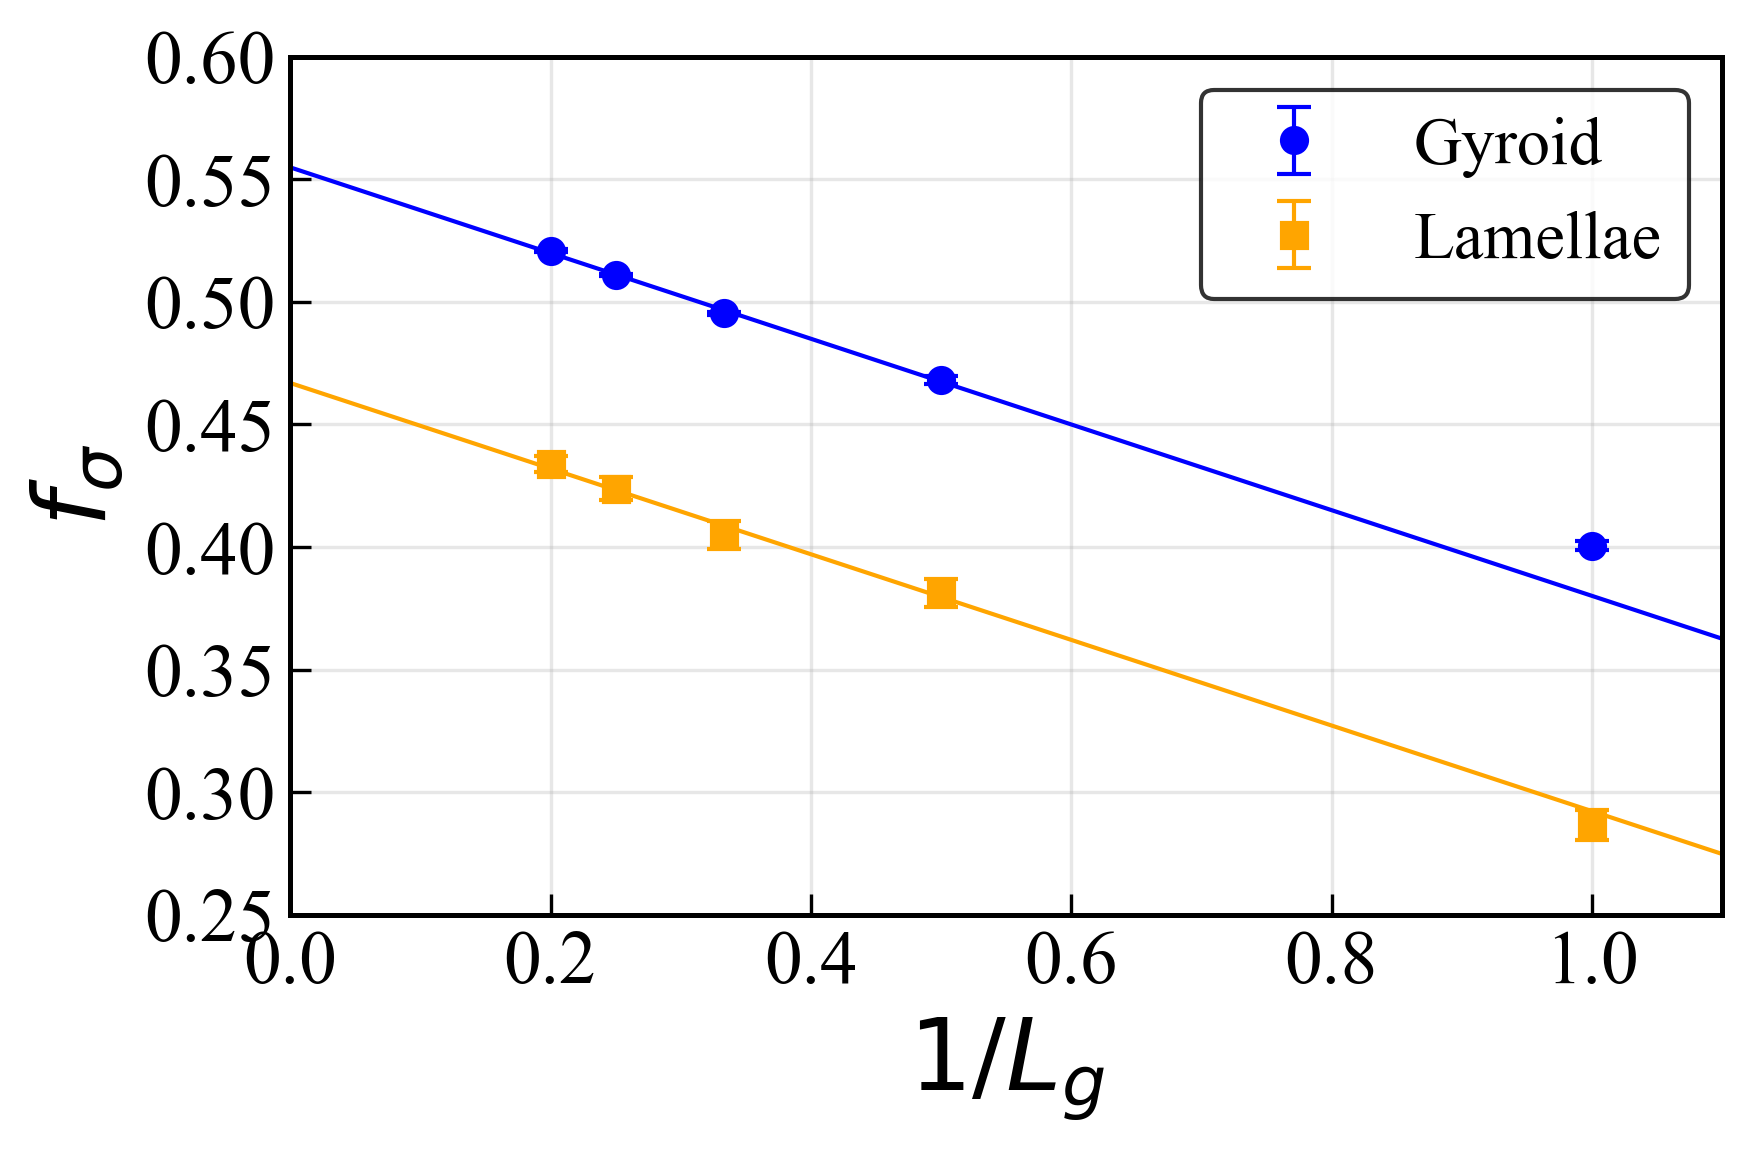

In [60]:
import numpy as np
from scipy.stats import linregress    # ← new
import matplotlib as mpl
import matplotlib.pyplot as plt

# Volume fractions of conducting phase
phi_l = 1/3
phi_g = 1/3

# Grid resolution corrections
grid_corr_g = 0.079882
grid_corr_l = 0.032248

# 1) conductivity arrays
cvg = np.load('cvg.npy') # gyroid
cvl = np.load('cvl.npy') # lamellar

x = np.array([1, 2, 3, 4, 5]) # L_g
x_inv = 1/x

cgyroid = (cvg[:-1, -1, :]) / phi_g + grid_corr_g # highest N_g
clamella = (cvl[:-1, -1, :]) / phi_l + grid_corr_l

cgyroid_mean = np.mean(cgyroid, axis=-1)
clamella_mean = np.mean(clamella, axis=-1)

cgyroid_std = np.std(cgyroid, axis=-1)
clamella_std = np.std(clamella, axis=-1)

# — fit with polyfit for plotting —
ml, bl = np.polyfit(x_inv[1:], clamella_mean[1:], 1)
mg, bg = np.polyfit(x_inv[1:], cgyroid_mean[1:], 1)

# — fit with linregress for statistics —
res_l = linregress(x_inv[1:], clamella_mean[1:])
res_g = linregress(x_inv[1:], cgyroid_mean[1:])

# compute RMSE
rmse_l = np.sqrt(np.mean((clamella_mean[1:] - (ml*x_inv[1:] + bl))**2))
rmse_g = np.sqrt(np.mean((cgyroid_mean[1:] - (mg*x_inv[1:] + bg))**2))

# print out intercepts and their errors
print(f"Lamellar intercept (bₗ) = {bl:.6f} ± {res_l.intercept_stderr:.6f}")
print(f"Gyroid    intercept (b_g) = {bg:.6f} ± {res_g.intercept_stderr:.6f}")
print(f"Lamellar RMSE = {rmse_l:.6f}")
print(f"Gyroid    RMSE = {rmse_g:.6f}")

# your plotting style
mpl.rcParams.update({
    'font.family':      'serif',
    'font.serif':       ['Times New Roman','Palatino','Georgia'],
    'font.size':        12,
    'axes.linewidth':   1.2,
    'xtick.direction':  'in',
    'ytick.direction':  'in',
    'xtick.major.size': 5,
    'ytick.major.size': 5,
    'legend.frameon':   False,
})

plt.figure(figsize=(6,4), dpi=300)

# Gyroid
plt.errorbar(
    x_inv, cgyroid_mean, yerr=cgyroid_std,
    fmt='o',           # circle markers with solid line
    capsize=4,          # horizontal bar length on error bars
    elinewidth=1,       # thickness of error bar lines
    markeredgewidth=1,
    label='Gyroid',
    color='blue'
)

# Lamellae
plt.errorbar(
    x_inv, clamella_mean, yerr=clamella_std,
    fmt='s',          # square markers with dashed line
    capsize=4,
    elinewidth=1,
    markeredgewidth=1,
    label='Lamellae',
    color='orange',
)

# fitted lines
x_lin = np.linspace(0, 1.1, 100)
plt.plot(x_lin, ml*x_lin + bl,
         linewidth=1,
         color='orange')    # ← simplified
plt.plot(x_lin, mg*x_lin + bg,
         linewidth=1,
         color='blue')      # ← simplified

plt.xlim(0, 1.1)
plt.ylim(0.25, 0.6)
plt.xlabel(r'$1 / L_g$', fontsize=24)
plt.ylabel(r'$f_{\sigma}$', fontsize=24)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.legend(fontsize=16, loc='upper right', frameon=True, facecolor='white', edgecolor='black')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('f_sigma_Lg_extrap.png', dpi=300)  # Save the figure
plt.show()


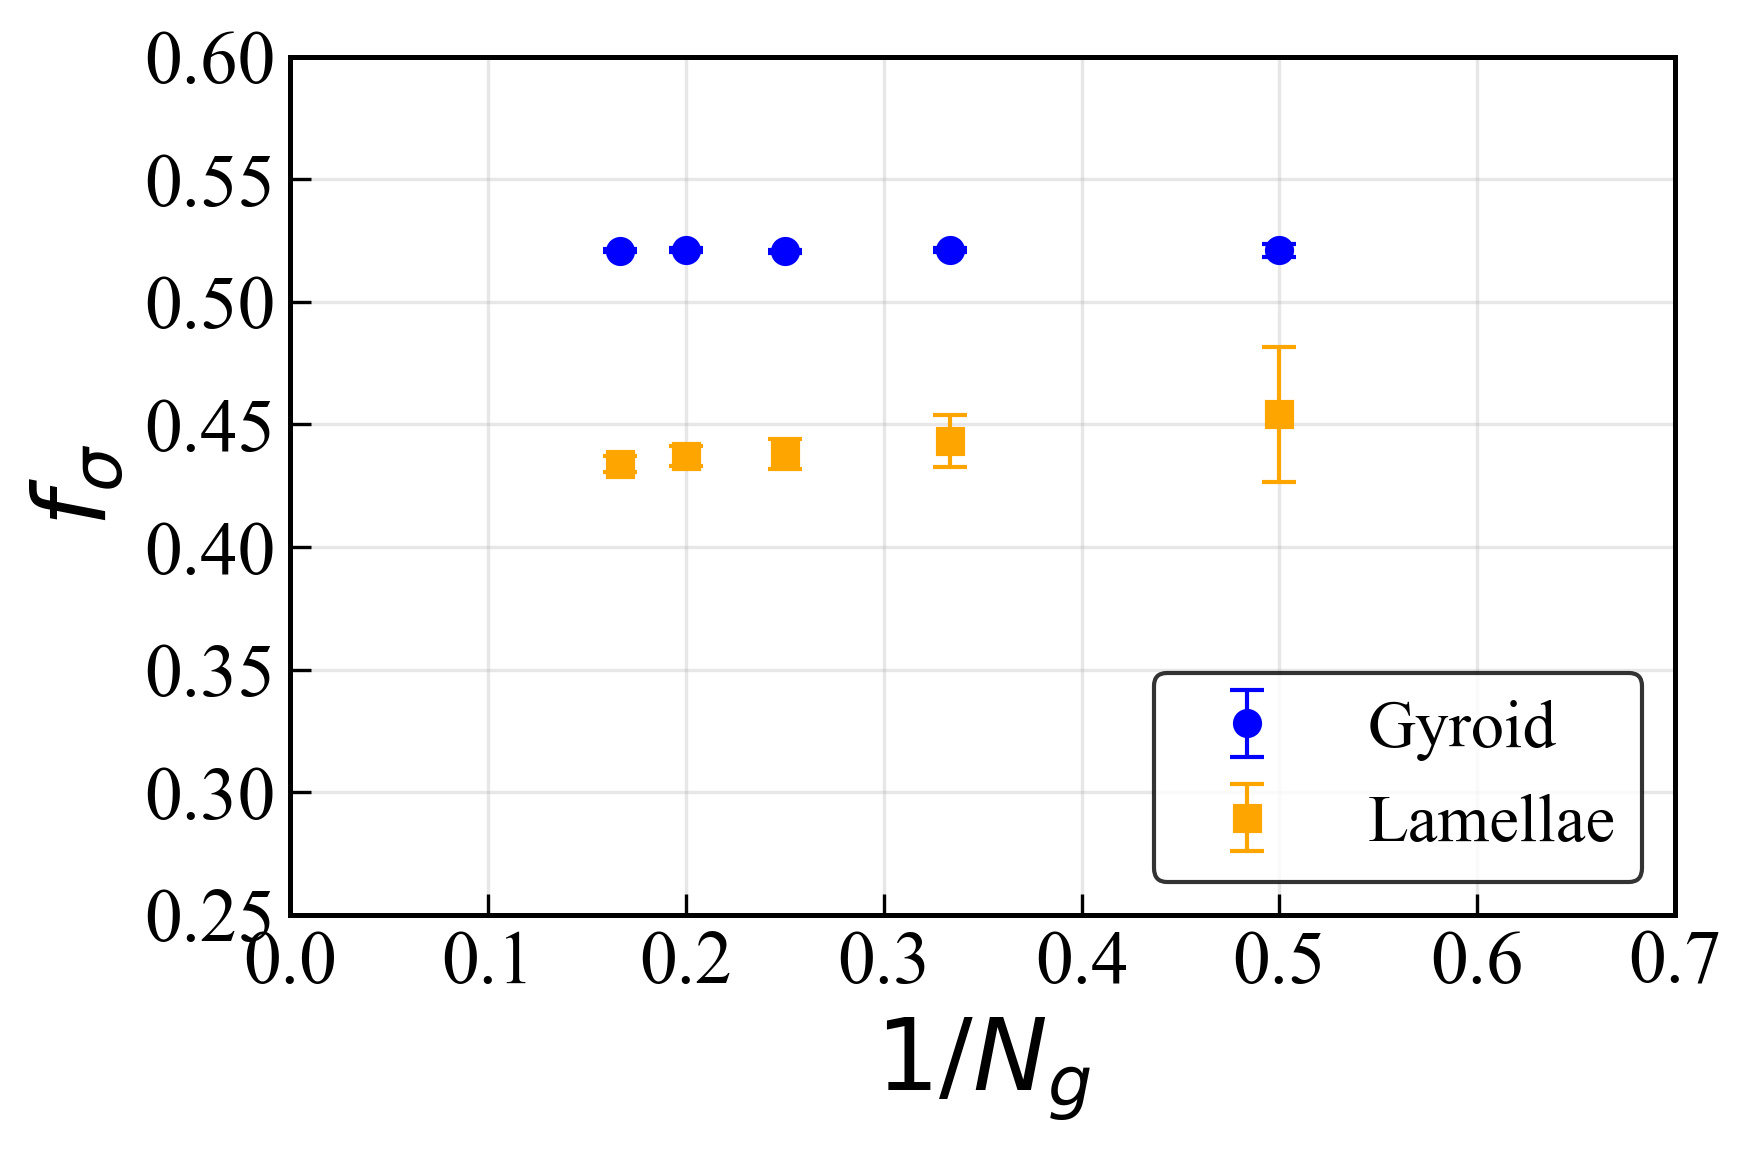

In [71]:
import numpy as np
from scipy.stats import linregress    # ← new
import matplotlib as mpl
import matplotlib.pyplot as plt

# Volume fractions of conducting phase
phi_l = 1/3
phi_g = 1/3

# Grid resolution corrections
grid_corr_g = 0.079882
grid_corr_l = 0.032248

# 1) conductivity arrays
cvg = np.load('cvg.npy') # gyroid
cvl = np.load('cvl.npy') # lamellar

x = np.array([2, 3, 4, 5, 6]) # N_g
x_inv = 1/x

cgyroid = (cvg[-2, 1:, :]) / phi_g + grid_corr_g # second highest L_g
clamella = (cvl[-2, 1:, :]) / phi_l + grid_corr_l

cgyroid_mean = np.mean(cgyroid, axis=-1)
clamella_mean = np.mean(clamella, axis=-1)

cgyroid_std = np.std(cgyroid, axis=-1)
clamella_std = np.std(clamella, axis=-1)

# your plotting style
mpl.rcParams.update({
    'font.family':      'serif',
    'font.serif':       ['Times New Roman','Palatino','Georgia'],
    'font.size':        12,
    'axes.linewidth':   1.2,
    'xtick.direction':  'in',
    'ytick.direction':  'in',
    'xtick.major.size': 5,
    'ytick.major.size': 5,
    'legend.frameon':   False,
})

plt.figure(figsize=(6,4), dpi=300)

# Gyroid
plt.errorbar(
    x_inv, cgyroid_mean, yerr=cgyroid_std,
    fmt='o',           # circle markers with solid line
    capsize=4,          # horizontal bar length on error bars
    elinewidth=1,       # thickness of error bar lines
    markeredgewidth=1,
    label='Gyroid',
    color='blue'
)

# Lamellae
plt.errorbar(
    x_inv, clamella_mean, yerr=clamella_std,
    fmt='s',          # square markers with dashed line
    capsize=4,
    elinewidth=1,
    markeredgewidth=1,
    label='Lamellae',
    color='orange'
)

plt.xlim(0, 0.7)
plt.ylim(0.25, 0.6)
plt.xlabel(r'$1 / N_g$', fontsize=24)
plt.ylabel(r'$f_{\sigma}$', fontsize=24)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.legend(fontsize=16, loc='lower right', frameon=True, facecolor='white', edgecolor='black')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('f_sigma_Ng_extrap.png', dpi=300)  # Save the figure

plt.show()


Lamellar intercept (bₗ) = 0.281702 ± 0.002498
Gyroid    intercept (b_g) = 0.558152 ± 0.000164
Lamellar RMSE = 0.001182
Gyroid    RMSE = 0.000077


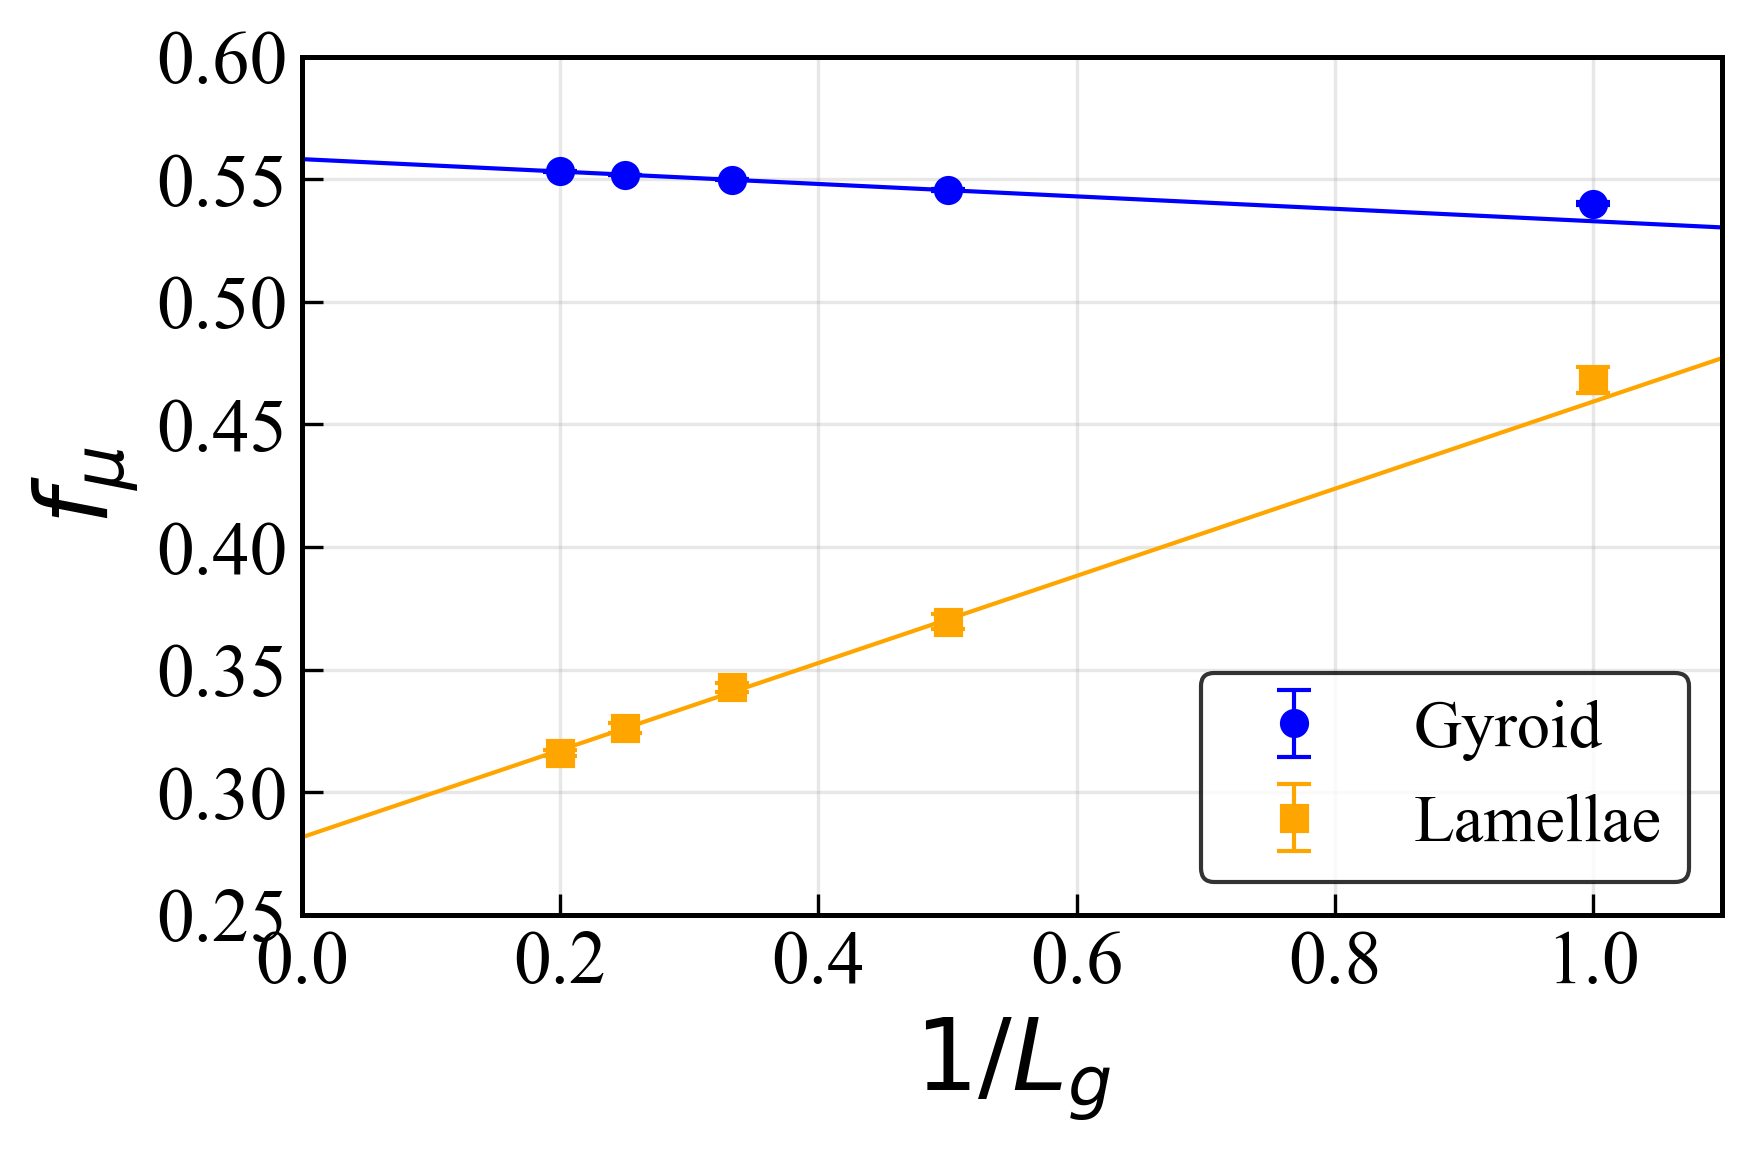

In [65]:
import numpy as np
from scipy.stats import linregress    # ← new
import matplotlib as mpl
import matplotlib.pyplot as plt

# Volume fractions of high shear phase
phi_l = 1-1/3
phi_g = 1-1/3

# Grid resolution corrections
grid_corr_g = 0.028590
grid_corr_l = 0.000107

# 1) conductivity arrays
evg = np.load('evg.npy') # gyroid
evl = np.load('evl.npy') # lamellar

x = np.array([1, 2, 3, 4, 5]) # L_g
x_inv = 1/x

egyroid = (evg[:-1, -1, :] ) / phi_g  + grid_corr_g
elamella = (evl[:-1, -1, :]) / phi_l  + grid_corr_l

egyroid_mean = np.mean(egyroid, axis=-1)
elamella_mean = np.mean(elamella, axis=-1)

egyroid_std = np.std(egyroid, axis=-1)
elamella_std = np.std(elamella, axis=-1)

# — fit with polyfit for plotting —
ml, bl = np.polyfit(x_inv[1:], elamella_mean[1:], 1)
mg, bg = np.polyfit(x_inv[1:], egyroid_mean[1:], 1)

# — fit with linregress for statistics —
res_l = linregress(x_inv[1:], elamella_mean[1:])
res_g = linregress(x_inv[1:], egyroid_mean[1:])

# compute RMSE
rmse_l = np.sqrt(np.mean((elamella_mean[1:] - (ml*x_inv[1:] + bl))**2))
rmse_g = np.sqrt(np.mean((egyroid_mean[1:] - (mg*x_inv[1:] + bg))**2))

# print out intercepts and their errors
print(f"Lamellar intercept (bₗ) = {bl:.6f} ± {res_l.intercept_stderr:.6f}")
print(f"Gyroid    intercept (b_g) = {bg:.6f} ± {res_g.intercept_stderr:.6f}")
print(f"Lamellar RMSE = {rmse_l:.6f}")
print(f"Gyroid    RMSE = {rmse_g:.6f}")

# your plotting style
mpl.rcParams.update({
    'font.family':      'serif',
    'font.serif':       ['Times New Roman','Palatino','Georgia'],
    'font.size':        12,
    'axes.linewidth':   1.2,
    'xtick.direction':  'in',
    'ytick.direction':  'in',
    'xtick.major.size': 5,
    'ytick.major.size': 5,
    'legend.frameon':   False,
})

plt.figure(figsize=(6,4), dpi=300)

# Gyroid
plt.errorbar(
    x_inv, egyroid_mean, yerr=egyroid_std,
    fmt='o',           # circle markers with solid line
    capsize=4,          # horizontal bar length on error bars
    elinewidth=1,       # thickness of error bar lines
    markeredgewidth=1,
    label='Gyroid',
    color='blue'
)

# Lamellae
plt.errorbar(
    x_inv, elamella_mean, yerr=elamella_std,
    fmt='s',          # square markers with dashed line
    capsize=4,
    elinewidth=1,
    markeredgewidth=1,
    label='Lamellae',
    color='orange'
)

# fitted lines
x_lin = np.linspace(0, 1.1, 100)
plt.plot(x_lin, ml*x_lin + bl,
         linewidth=1,
         color='orange')    # ← simplified
plt.plot(x_lin, mg*x_lin + bg,
         linewidth=1,
         color='blue')      # ← simplified

plt.xlim(0, 1.1)
plt.ylim(0.25, 0.6)
plt.xlabel(r'$1 / L_g$', fontsize=24)
plt.ylabel(r'$f_{\mu}$', fontsize=24)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.legend(fontsize=16, loc='lower right', frameon=True, facecolor='white', edgecolor='black')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('f_mu_Lg_extrap.png', dpi=300)  # Save the figure
plt.show()


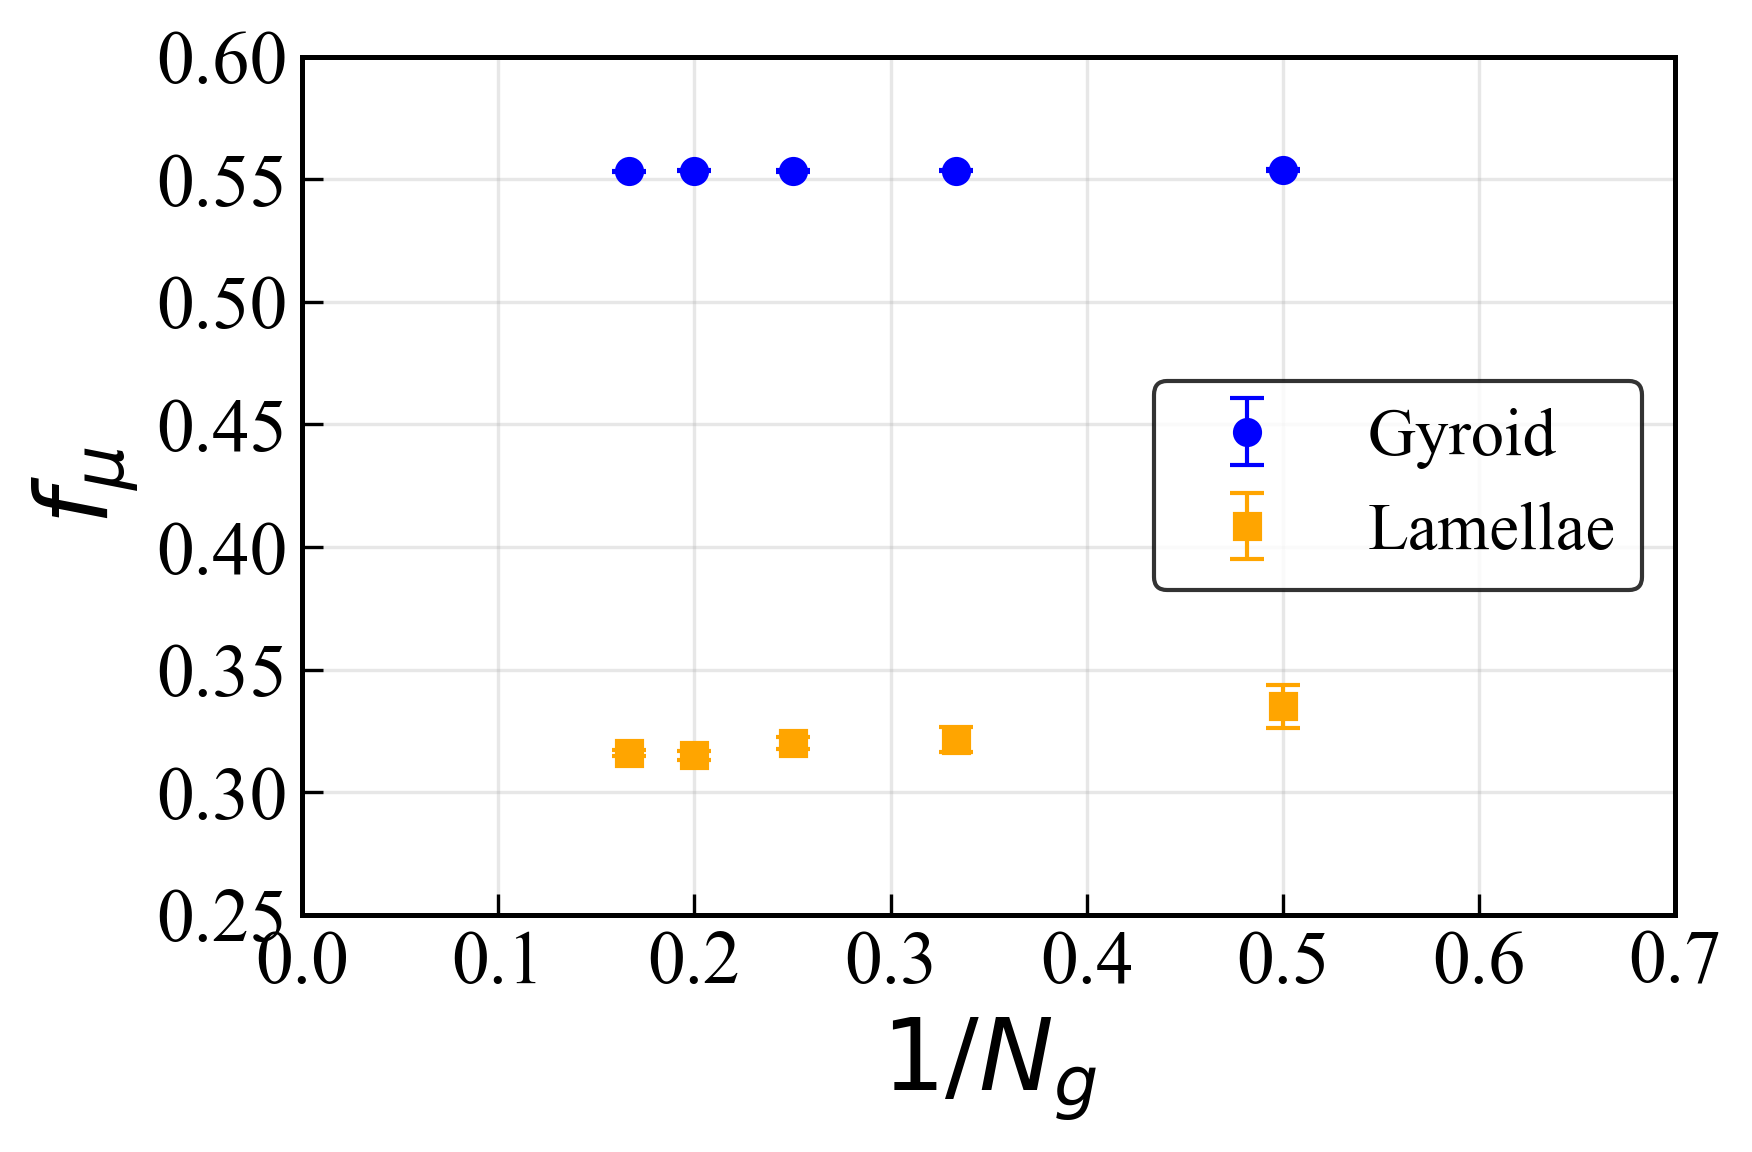

In [66]:
import numpy as np
from scipy.stats import linregress    # ← new
import matplotlib as mpl
import matplotlib.pyplot as plt

# Volume fractions of high shear phase
phi_l = 1-1/3
phi_g = 1-1/3

# Grid resolution corrections
grid_corr_g = 0.028590
grid_corr_l = 0.000107

# 1) conductivity arrays
cvg = np.load('evg.npy') # gyroid
cvl = np.load('evl.npy') # lamellar

x = np.array([2, 3, 4, 5, 6]) # N_g
x_inv = 1/x

cgyroid = (cvg[-2, 1:, :]) / phi_g  + grid_corr_g
clamella = (cvl[-2, 1:, :]) / phi_l  + grid_corr_l

cgyroid_mean = np.mean(cgyroid, axis=-1)
clamella_mean = np.mean(clamella, axis=-1)

cgyroid_std = np.std(cgyroid, axis=-1)
clamella_std = np.std(clamella, axis=-1)



# your plotting style
mpl.rcParams.update({
    'font.family':      'serif',
    'font.serif':       ['Times New Roman','Palatino','Georgia'],
    'font.size':        12,
    'axes.linewidth':   1.2,
    'xtick.direction':  'in',
    'ytick.direction':  'in',
    'xtick.major.size': 5,
    'ytick.major.size': 5,
    'legend.frameon':   False,
})

plt.figure(figsize=(6,4), dpi=300)

# Gyroid
plt.errorbar(
    x_inv, cgyroid_mean, yerr=cgyroid_std,
    fmt='o',           # circle markers with solid line
    capsize=4,          # horizontal bar length on error bars
    elinewidth=1,       # thickness of error bar lines
    markeredgewidth=1,
    label='Gyroid',
    color='blue'
)

# Lamellae
plt.errorbar(
    x_inv, clamella_mean, yerr=clamella_std,
    fmt='s',          # square markers with dashed line
    capsize=4,
    elinewidth=1,
    markeredgewidth=1,
    label='Lamellae',
    color='orange'
)

plt.xlim(0, 0.7)
plt.ylim(0.25, 0.6)
plt.xlabel(r'$1 / N_g$', fontsize=24)
plt.ylabel(r'$f_{\mu}$', fontsize=24)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.legend(fontsize=16, loc='center right', frameon=True, facecolor='white', edgecolor='black')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('f_mu_Ng_extrap.png', dpi=300)  # Save the figure
plt.show()



Lamellar intercept (bₗ) = 0.397436 ± 0.000452
Gyroid    intercept (b_g) = 0.471957 ± 0.000642
Lamellar RMSE = 0.000312
Gyroid    RMSE = 0.000443

Lamellar grid resolution correction: 0.032248
Gyroid grid resolution correction: 0.079882


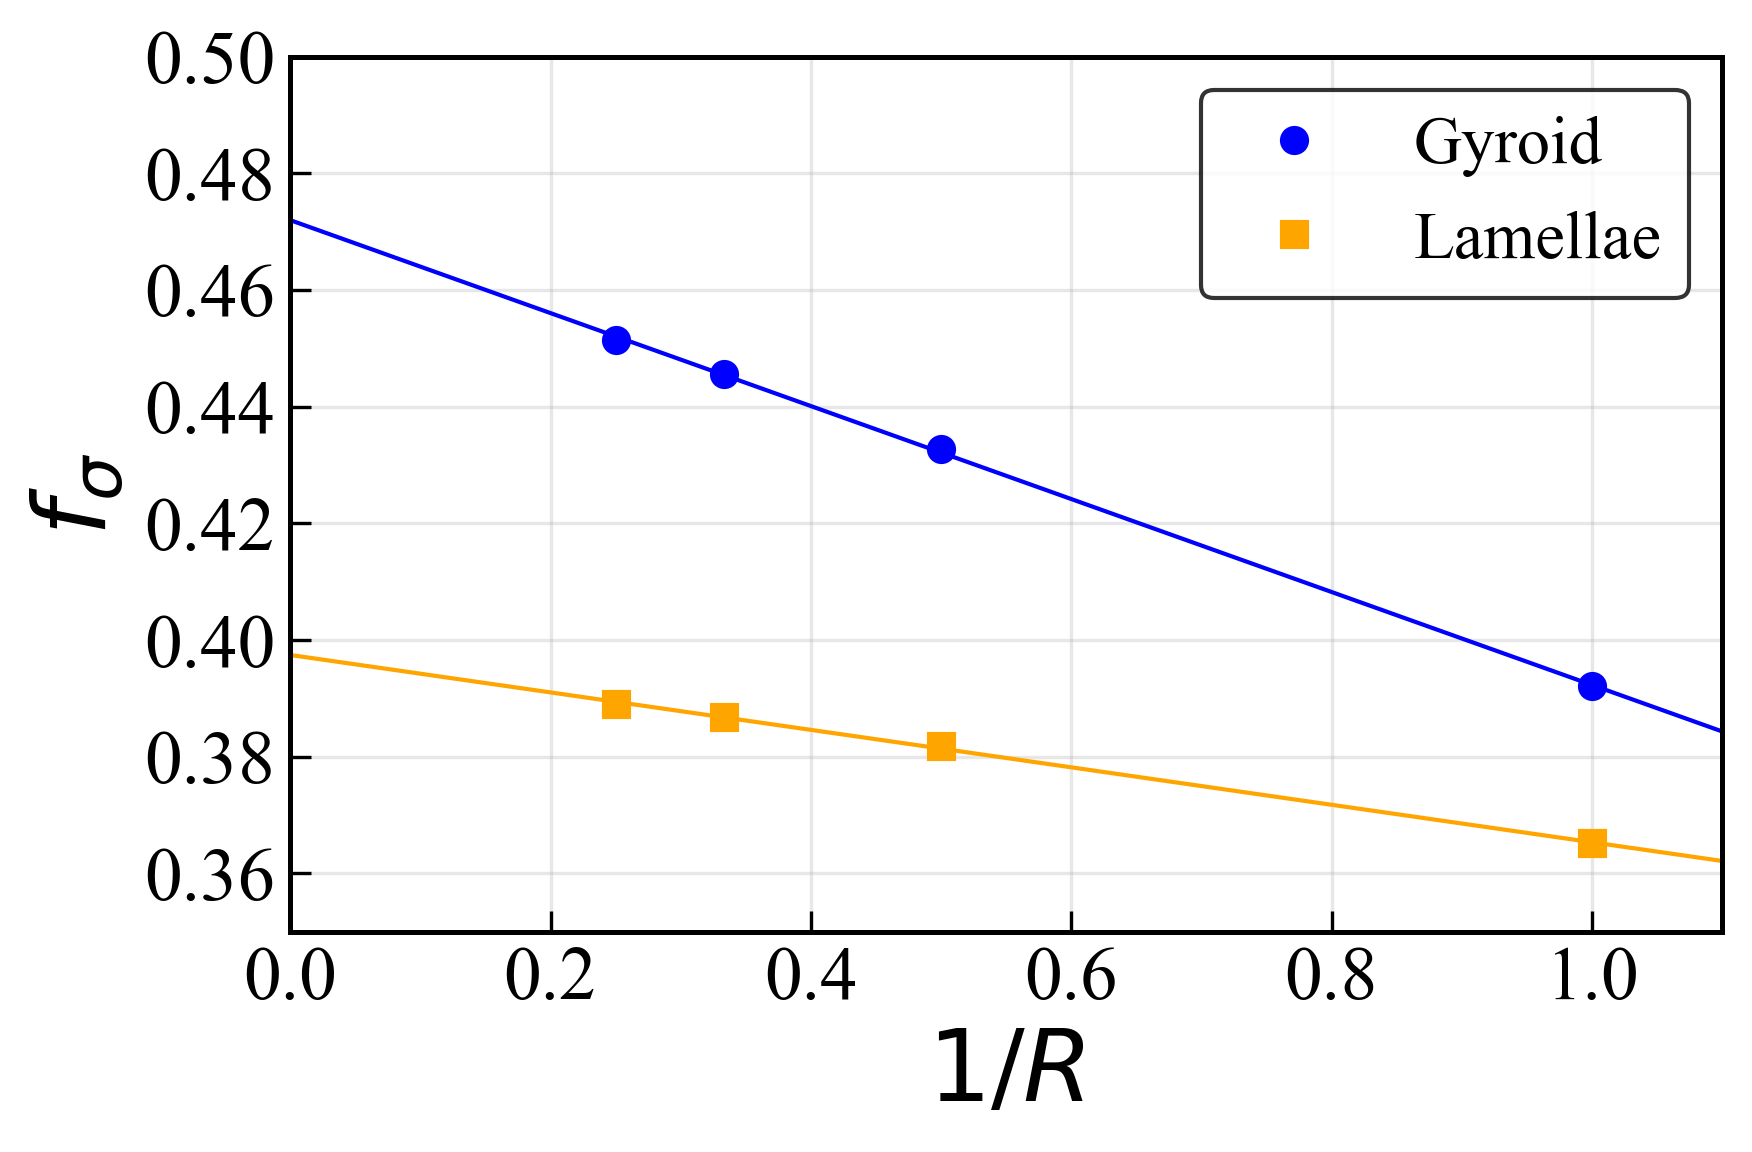

In [69]:
# Effect of grid resolution on conductivity
import numpy as np
from scipy.stats import linregress    # ← new
import matplotlib as mpl
import matplotlib.pyplot as plt

# Volume fractions of high shear phase
phi_l = 1/3
phi_g = 1/3

# 1) conductivity arrays
cvg = np.array([0.1306915581226349, 0.14425460994243622, 0.14851844310760498, 0.15049594640731812])
cvl = np.array([0.12172925472259521, 0.12726858258247375, 0.12896260619163513, 0.12966741621494293])

x = np.array([1,2,3,4]) # N_g
x_inv = 1/x

cgyroid = cvg / phi_g # highest L_g
clamella = cvl / phi_l

# — fit with polyfit for plotting —
ml, bl = np.polyfit(x_inv, clamella, 1)
mg, bg = np.polyfit(x_inv, cgyroid, 1)

# — fit with linregress for statistics —
res_l = linregress(x_inv, clamella)
res_g = linregress(x_inv, cgyroid)

# compute RMSE
rmse_l = np.sqrt(np.mean((clamella - (ml*x_inv + bl))**2))
rmse_g = np.sqrt(np.mean((cgyroid - (mg*x_inv + bg))**2))

# print out intercepts and their errors
print(f"Lamellar intercept (bₗ) = {bl:.6f} ± {res_l.intercept_stderr:.6f}")
print(f"Gyroid    intercept (b_g) = {bg:.6f} ± {res_g.intercept_stderr:.6f}")
print(f"Lamellar RMSE = {rmse_l:.6f}")
print(f"Gyroid    RMSE = {rmse_g:.6f}")

print(f"\nLamellar grid resolution correction: {bl - clamella[0]:.6f}")
print(f"Gyroid grid resolution correction: {bg - cgyroid[0]:.6f}")

# your plotting style
mpl.rcParams.update({
    'font.family':      'serif',
    'font.serif':       ['Times New Roman','Palatino','Georgia'],
    'font.size':        12,
    'axes.linewidth':   1.2,
    'xtick.direction':  'in',
    'ytick.direction':  'in',
    'xtick.major.size': 5,
    'ytick.major.size': 5,
    'legend.frameon':   False,
})

plt.figure(figsize=(6,4), dpi=300)

# Gyroid
plt.errorbar(
    x_inv, cgyroid,
    fmt='o',           # circle markers with solid line
    label='Gyroid',
    color='blue'
)

# Lamellae
plt.errorbar(
    x_inv, clamella,
    fmt='s',          # square markers with dashed line
    label='Lamellae',
    color='orange'
)

# fitted lines
x_lin = np.linspace(0, 1.1, 100)
plt.plot(x_lin, ml*x_lin + bl,
         linewidth=1,
         color='orange')    # ← simplified
plt.plot(x_lin, mg*x_lin + bg,
         linewidth=1,
         color='blue')      # ← simplified

plt.xlim(0, 1.1)
plt.ylim(0.35, 0.5)
plt.xlabel(r'$1 / R$', fontsize=24)
plt.ylabel(r'$f_{\sigma}$', fontsize=24)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.legend(fontsize=16, loc='upper right', frameon=True, facecolor='white', edgecolor='black')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('f_sigma_res_extrap.png', dpi=300)  # Save the figure
plt.show()

Lamellar intercept (bₗ) = 0.357332 ± 0.000355
Gyroid    intercept (b_g) = 0.545056 ± 0.002078
Lamellar RMSE = 0.000245
Gyroid    RMSE = 0.001433

Lamellar grid resolution correction: 0.000107
Gyroid grid resolution correction: 0.028590


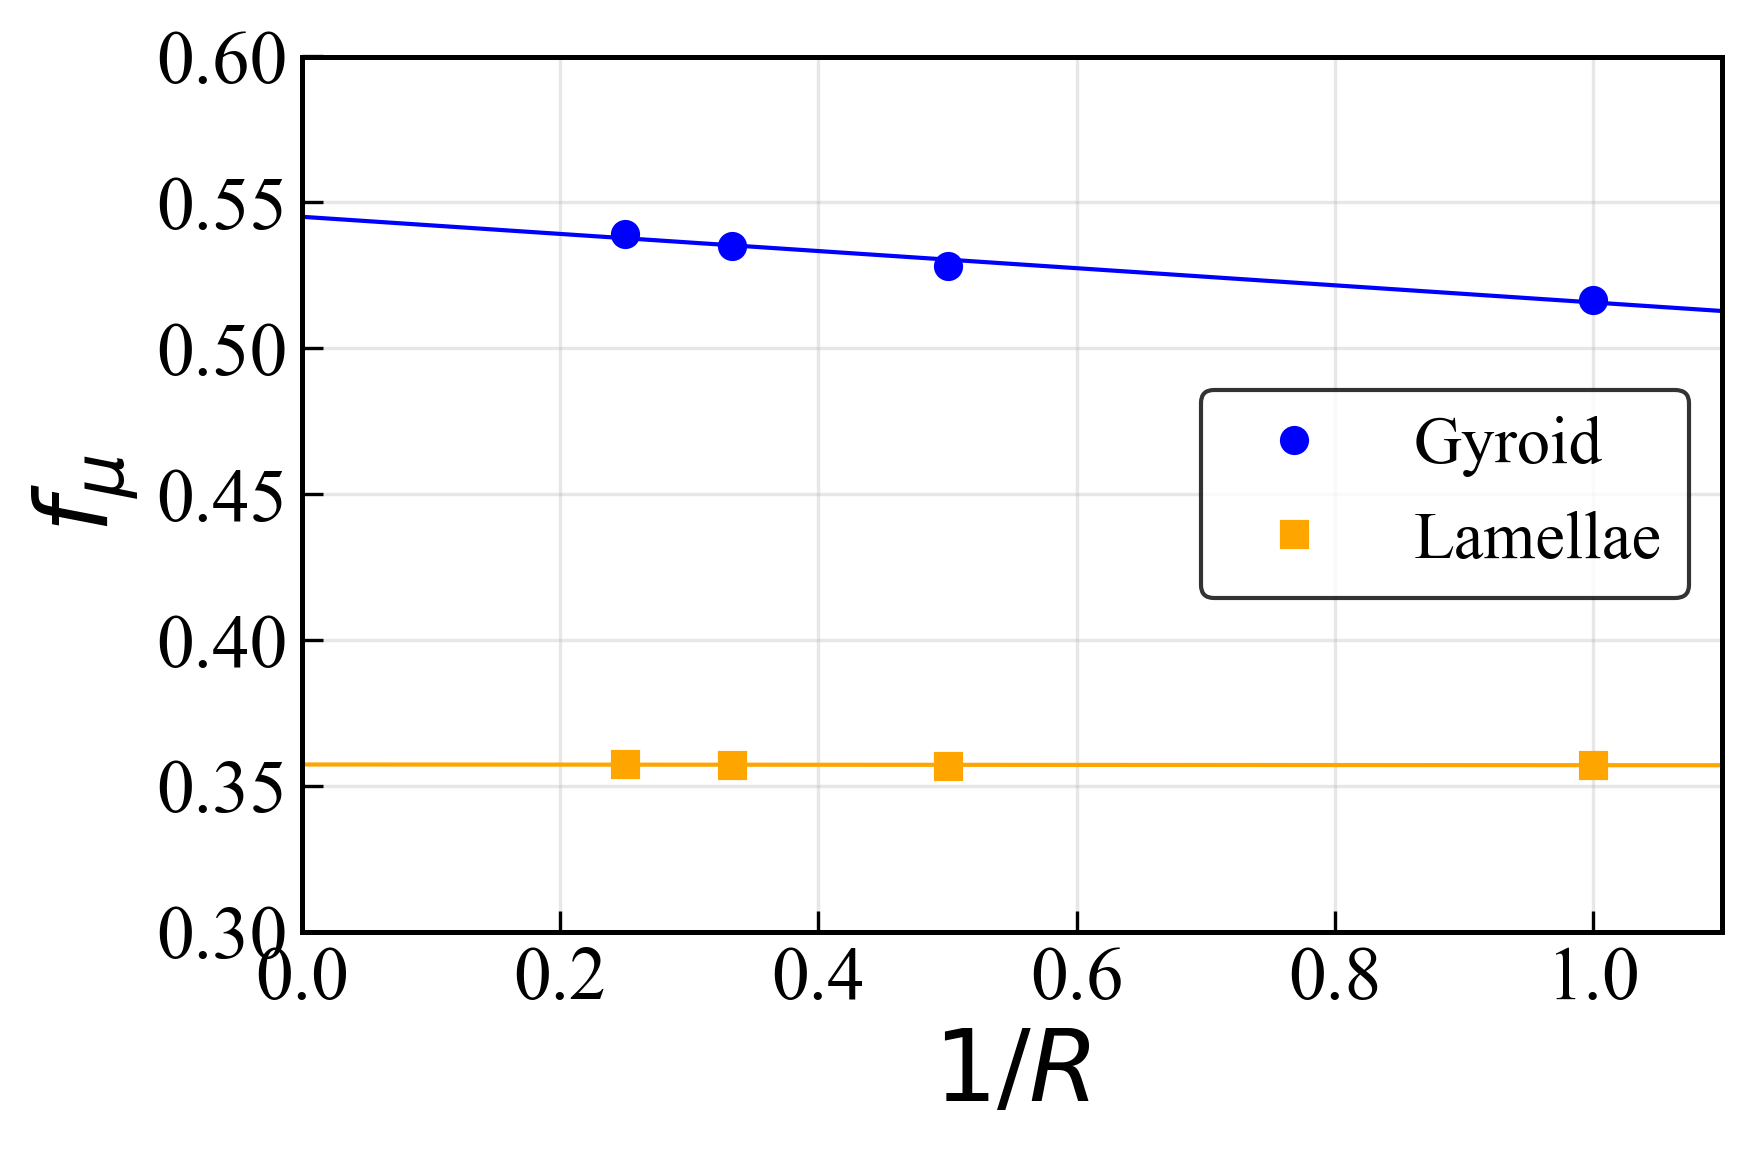

In [70]:
# Effect of grid resolution on conductivity
import numpy as np
from scipy.stats import linregress    # ← new
import matplotlib as mpl
import matplotlib.pyplot as plt

# Volume fractions of high shear phase
phi_l = 1-1/3
phi_g = 1-1/3

# 1) conductivity arrays
cvg = np.array([0.34431013464927673, 0.3520888388156891, 0.35676679015159607, 0.35954830050468445])
cvl = np.array([0.23814992606639862, 0.23788347840309143, 0.23816004395484924, 0.23836146295070648])

x = np.array([1,2,3,4]) # N_g
x_inv = 1/x

cgyroid = cvg / phi_g # highest L_g
clamella = cvl / phi_l

# — fit with polyfit for plotting —
ml, bl = np.polyfit(x_inv, clamella, 1)
mg, bg = np.polyfit(x_inv, cgyroid, 1)

# — fit with linregress for statistics —
res_l = linregress(x_inv, clamella)
res_g = linregress(x_inv, cgyroid)

# compute RMSE
rmse_l = np.sqrt(np.mean((clamella - (ml*x_inv + bl))**2))
rmse_g = np.sqrt(np.mean((cgyroid - (mg*x_inv + bg))**2))

# print out intercepts and their errors
print(f"Lamellar intercept (bₗ) = {bl:.6f} ± {res_l.intercept_stderr:.6f}")
print(f"Gyroid    intercept (b_g) = {bg:.6f} ± {res_g.intercept_stderr:.6f}")
print(f"Lamellar RMSE = {rmse_l:.6f}")
print(f"Gyroid    RMSE = {rmse_g:.6f}")

print(f"\nLamellar grid resolution correction: {bl - clamella[0]:.6f}")
print(f"Gyroid grid resolution correction: {bg - cgyroid[0]:.6f}")

# your plotting style
mpl.rcParams.update({
    'font.family':      'serif',
    'font.serif':       ['Times New Roman','Palatino','Georgia'],
    'font.size':        12,
    'axes.linewidth':   1.2,
    'xtick.direction':  'in',
    'ytick.direction':  'in',
    'xtick.major.size': 5,
    'ytick.major.size': 5,
    'legend.frameon':   False,
})

plt.figure(figsize=(6,4), dpi=300)

# Gyroid
plt.errorbar(
    x_inv, cgyroid,
    fmt='o',           # circle markers with solid line
    label='Gyroid',
    color='blue'
)

# Lamellae
plt.errorbar(
    x_inv, clamella,
    fmt='s',          # square markers with dashed line
    label='Lamellae',
    color='orange'
)

# fitted lines
x_lin = np.linspace(0, 1.1, 100)
plt.plot(x_lin, ml*x_lin + bl,
         linewidth=1,
         color='orange')    # ← simplified
plt.plot(x_lin, mg*x_lin + bg,
         linewidth=1,
         color='blue')      # ← simplified

plt.xlim(0, 1.1)
plt.ylim(0.3, 0.6)
plt.xlabel(r'$1 / R$', fontsize=24)
plt.ylabel(r'$f_{\mu}$', fontsize=24)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.legend(fontsize=16, loc='center right', frameon=True, facecolor='white', edgecolor='black')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('f_mu_res_extrap.png', dpi=300)  # Save the figure
plt.show()